In [2]:
# Global Imports and Runtime Visual Configuration
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sqlite3

# Visual styling settings
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["figure.figsize"] = (8, 4)
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.labelsize"] = 10

print("Global libraries for SQL relational database analytics loaded successfully.")

Global libraries for SQL relational database analytics loaded successfully.


# Table of Contents
- 1. Conditional Aggregations (`CASE WHEN`)
- 2. HAVING Clauses and Complex Filtering
- 3. Rollup, Cube, and Grouping Sets
- 4. Handling NULLs in Database Calculations

Conditional aggregation result:   region  online_sales  store_sales
0  North           350          200
1  South           150          300


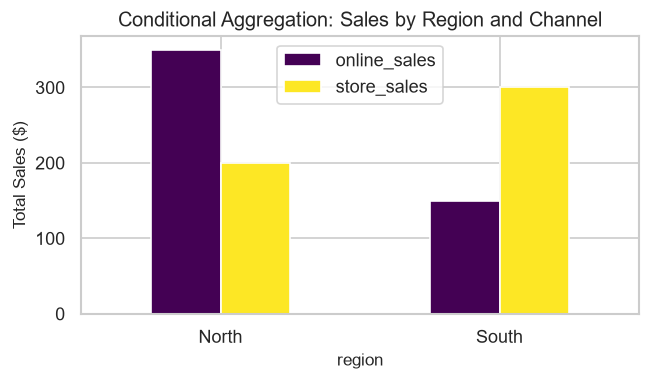

In [4]:
# 1 Conditional Aggregations (`CASE WHEN`)
conn = sqlite3.connect(':memory:')
df_sales = pd.DataFrame({
    'region': ['North', 'North', 'South', 'South', 'North'],
    'channel': ['Online', 'Store', 'Online', 'Store', 'Online'],
    'amount': [100, 200, 150, 300, 250]
})
df_sales.to_sql('sales', conn, index=False, if_exists='replace')

query = """
SELECT
    region,
    SUM(CASE WHEN channel = 'Online' THEN amount ELSE 0 END) AS online_sales,
    SUM(CASE WHEN channel = 'Store' THEN amount ELSE 0 END) AS store_sales
FROM sales
GROUP BY region
"""
df_result = pd.read_sql(query, conn)
print("Conditional aggregation result:", df_result)

# Visualization
plt.figure(figsize=(6, 3))
df_result.set_index('region').plot(kind='bar', ax=plt.gca(), colormap='viridis')
plt.title('Conditional Aggregation: Sales by Region and Channel')
plt.ylabel('Total Sales ($)')
plt.xticks(rotation=0)
plt.show()

HAVING clause result:   department  avg_salary
0         IT     85000.0
1      Sales     71000.0


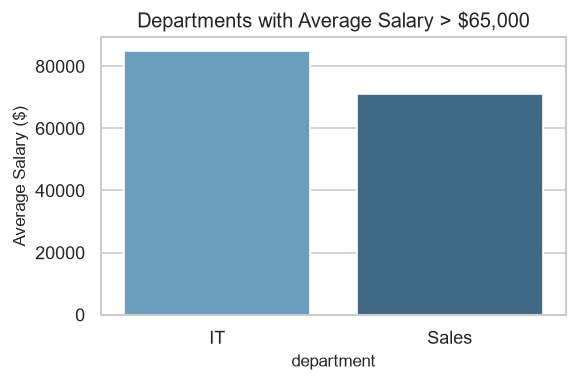

In [6]:
# 2. HAVING Clauses and Complex Filtering
df_emp = pd.DataFrame({
    'department': ['IT', 'IT', 'HR', 'HR', 'Sales', 'Sales'],
    'salary': [80000, 90000, 50000, 55000, 70000, 72000]
})
df_emp.to_sql('employees', conn, index=False, if_exists='replace')

query = """
SELECT
    department,
    AVG(salary) AS avg_salary
FROM employees
GROUP BY department
HAVING AVG(salary) > 60000
"""
df_result = pd.read_sql(query, conn)
print("HAVING clause result:", df_result)

# Visualization
plt.figure(figsize=(5, 3))
sns.barplot(x='department', y='avg_salary', hue='department', data=df_result, palette='Blues_d', legend=False, errorbar=None)
plt.title('Departments with Average Salary > $65,000')
plt.ylabel('Average Salary ($)')
plt.show()

In [12]:
# 3. Rollup, Cube, and Grouping Sets

def get_df():
    # 1. Create an in-memory Pandas DataFrame
    df = pd.DataFrame({
        'region': ['East', 'East', 'West', 'West', 'North'],
        'category': ['Tech', 'Furniture', 'Tech', 'Furniture', 'Tech'],
        'sales': [120, 230, 150, 300, 180]
    })
    return df

def create_db(df):
    # 2. Feed into an in-memory SQLite3 database
    conn = sqlite3.connect(':memory:')
    df.to_sql('sales_data', conn, index=False, if_exists='replace')
    return conn

def grouping_sets_query(conn): # groupsets are use d for hierarchical aggregations
        query_grouping_sets ="""
        -- Bucket 1: Grouped by both Region and Category
        SELECT region, category, SUM(sales) AS total_sales 
        FROM sales_data 
        GROUP BY region, category

        UNION ALL

        -- Bucket 2: Subtotal by Region only
        SELECT region, 'ALL_CATEGORIES' AS category, SUM(sales) AS total_sales 
        FROM sales_data 
        GROUP BY region

        UNION ALL

        -- Bucket 3: Grand Total (empty set)
        SELECT 'ALL_REGIONS' AS region, 'ALL_CATEGORIES' AS category, SUM(sales) AS total_sales 
        FROM sales_data;
        """
        df_gs = pd.read_sql(query_grouping_sets, conn)
        print("--- GROUPING SETS Equivalent ---")
        print(df_gs)

def cube_query (conn): # CUBE is used to generate subtotals for all combinations of specified columns
        query_cube = """
        -- Combination 1: Both Region and Category
        SELECT region, category, SUM(sales) AS total_sales 
        FROM sales_data 
        GROUP BY region, category

        UNION ALL

        -- Combination 2: Region subtotal (across all categories)
        SELECT region, 'ALL_CATEGORIES' AS category, SUM(sales) AS total_sales 
        FROM sales_data 
        GROUP BY region

        UNION ALL

        -- Combination 3: Category subtotal (across all regions)
        SELECT 'ALL_REGIONS' AS region, category, SUM(sales) AS total_sales 
        FROM sales_data 
        GROUP BY category

        UNION ALL

        -- Combination 4: Grand Total
        SELECT 'ALL_REGIONS' AS region, 'ALL_CATEGORIES' AS category, SUM(sales) AS total_sales 
        FROM sales_data;
        """

        df_cube = pd.read_sql(query_cube, conn)
        print("\n--- CUBE Equivalent ---")
        print(df_cube)
    

def rollup_query(conn): # used for hierarchical aggregations
    query_rollup = """
    -- Level 1: Detail level (Region + Category)
    SELECT region, category, SUM(sales) AS total_sales 
    FROM sales_data 
    GROUP BY region, category

    UNION ALL

    -- Level 2: Subtotal rolled up by Region
    SELECT region, 'SUBTOTAL' AS category, SUM(sales) AS total_sales 
    FROM sales_data 
    GROUP BY region

    UNION ALL

    -- Level 3: Grand Total
    SELECT 'GRAND_TOTAL' AS region, 'GRAND_TOTAL' AS category, SUM(sales) AS total_sales 
    FROM sales_data;
    """

    df_rollup = pd.read_sql(query_rollup, conn)
    print("\n--- ROLLUP Equivalent ---")
    print(df_rollup)

if __name__ == "__main__":
    df = get_df()
    conn = create_db(df)
    # grouping_sets_query(conn)
    rollup_query(conn)
    # cube_query(conn)


--- ROLLUP Equivalent ---
        region     category  total_sales
0         East    Furniture          230
1         East         Tech          120
2        North         Tech          180
3         West    Furniture          300
4         West         Tech          150
5         East     SUBTOTAL          350
6        North     SUBTOTAL          180
7         West     SUBTOTAL          450
8  GRAND_TOTAL  GRAND_TOTAL          980


Groupby Summary Table (Rollup Simulation):
   region   product  sales
0  North  Widget A    100
1  North  Widget B    150
2  South  Widget A    200
3  South  Widget B    250


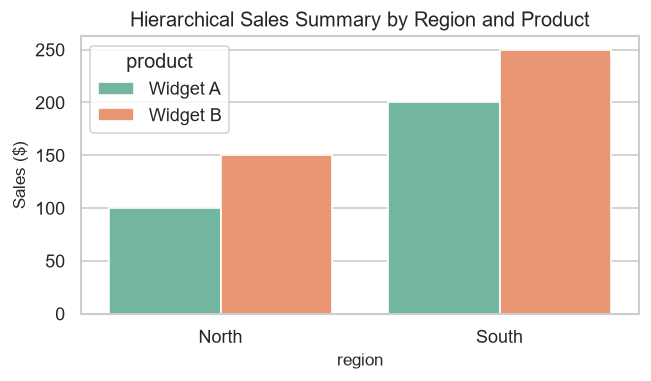

In [13]:
# 6. & 7. Implementation and Visualization (Pandas Groupby aggregation simulation for rollup)
df_rollup = pd.DataFrame({
    'region': ['North', 'North', 'South', 'South'],
    'product': ['Widget A', 'Widget B', 'Widget A', 'Widget B'],
    'sales': [100, 150, 200, 250]
})

# Simulated Rollup summary
rollup_res = df_rollup.groupby(['region', 'product'])['sales'].sum().reset_index()
print(
    "Groupby Summary Table (Rollup Simulation):\n",
    rollup_res,
)

# Visualization
plt.figure(figsize=(6, 3))
sns.barplot(x='region', y='sales', hue='product', data=rollup_res, palette='Set2', errorbar=None)
plt.title('Hierarchical Sales Summary by Region and Product')
plt.ylabel('Sales ($)')
plt.show()

`COALESCE(x, y, 0)` evaluates arguments sequentially and returns the first non-null value:
$$\text{COALESCE}(x, y) = \begin{cases} x & \text{if } x \neq \text{NULL} \\ y & \text{if } x = \text{NULL} \text{ and } y \neq \text{NULL} \end{cases}$$

Handling NULLs with COALESCE:
   employee   base  fixed_bonus  total_comp
0    Alice  50000       5000.0     55000.0
1      Bob  60000          0.0     60000.0
2  Charlie  70000      10000.0     80000.0


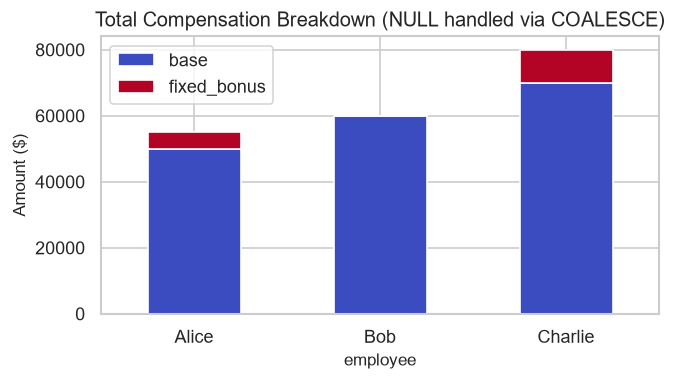

In [15]:
df_nulls = pd.DataFrame({
    'employee': ['Alice', 'Bob', 'Charlie'],
    'base': [50000, 60000, 70000],
    'bonus': [5000, None, 10000]
})
df_nulls.to_sql('comp', conn, index=False, if_exists="replace")

# SQL Coalesce Query
query_nulls = '''
    SELECT employee, base, COALESCE(bonus, 0) as fixed_bonus,
           (base + COALESCE(bonus, 0)) as total_comp
    FROM comp
'''
res_nulls = pd.read_sql(query_nulls, conn)
print("Handling NULLs with COALESCE:\n", res_nulls)


# Visualization
plt.figure(figsize=(6, 3))
res_nulls.set_index('employee')[['base', 'fixed_bonus']].plot(kind='bar', stacked=True, ax=plt.gca(), colormap='coolwarm')
plt.title('Total Compensation Breakdown (NULL handled via COALESCE)')
plt.ylabel('Amount ($)')
plt.xticks(rotation=0)
plt.show()

---
## Summary Table

| SQL Aggregation Technique | Primary Clause / Function | Core Objective | Primary Analytical Purpose |
| :--- | :--- | :--- | :--- |
| **Conditional Aggregations** | `SUM(CASE WHEN ...)` | Pivoting & conditional calculation | Computing multiple segmented metrics in a single pass |
| **HAVING Clauses** | `HAVING AVG(...) > threshold` | Filtering group-level summaries | Restricting aggregated output rows based on conditions |
| **Rollup & Grouping Sets** | `ROLLUP`, `CUBE`, `GROUPING SETS` | Multi-level subtotal generation | OLAP reporting with hierarchical subtotals and totals |
| **Handling NULLs** | `COALESCE()`, `IFNULL()` | Managing missing value arithmetic | Preventing NULL propagation in database calculations |